# Wolf reintroduction: from extinction to recovery

**Question:** Starting from the wolf-free Yellowstone produced by our extinction model, how big does a reintroduction need to be, and how strong does legal protection need to be, for wolves to recover and stay recovered? And how much do those answers depend on where we start and on the parameter values we picked?

**Scenarios compared:**
1. No reintroduction (baseline)
2. Reintroduction with no protection
3. Reintroduction plus protection (like Yellowstone 1995–2011)
4. Reintroduction, protection, then delisting with regulated hunting
5. Reintroduction, protection, then a return to extinction-era pressure

**Why it matters.** Wolves were removed from Yellowstone by people, not by a lack of food, and they came back because of a deliberate policy. A model that links the two halves of that story, extinction and recovery, lets us ask which part of the policy actually did the work: the animals released, or the protection afterwards. We expect protection to decide *whether* wolves recover and release size to decide mostly *how fast*, unless small packs struggle to reproduce (an Allee effect).

## 1. Background: what actually happened

- **Extinction:** Government predator-control programs, aimed at protecting livestock and "good" game such as elk, killed wolves throughout the region. The last Yellowstone pack was killed in 1926. With no wolves, northern-range elk grew to very high numbers and heavily browsed willow and aspen.
- **Releases:** 14 wolves from Alberta were released in January 1995 and 17 from British Columbia in January 1996, about 31 in total. They were *soft releases*: family groups were held in acclimation pens for roughly 8–10 weeks before the gates were opened, which reduced homing and kept packs together.
- **Protection:** The wolves were designated an ESA Section 10(j) "experimental, nonessential" population. That kept them protected, but it still allowed ranchers and agencies to kill wolves that attacked livestock. Protection was strong but not total. A district court ordered the wolves removed in 1997, and the 10th Circuit reversed that ruling in 2000 (*Wyoming Farm Bureau Federation v. Babbitt*).
- **Compensation:** A private fund paid ranchers for livestock lost to wolves. This lowered the incentive to kill wolves illegally, which in our model means a lower farmer removal rate.
- **Delisting:** Wolves in the Northern Rockies passed their recovery targets, and Montana and Idaho wolves were delisted in 2011 (Wyoming later). Hunting is now allowed outside the park but not inside it.
- **Recent numbers:** The park has held roughly 100 wolves in recent years, and the Northern Rockies population was about 1,600 around 2010.

**How each fact becomes a model term.** Populations in the model are scaled indices. We calibrate the protected equilibrium (about 10.7 wolf units) to the roughly 100 wolves in the park, so **1 wolf unit ≈ 10 real wolves**.

| Real-world fact | Model term | Value chosen | Justification |
|---|---|---|---|
| Decades of wolf extermination | $h_W = 0.35$, $p_F = 0.45$ | from `demo_wolf_extinction.py` | Strong enough that wolves cannot persist: human-caused wolf deaths of 0.8/yr exceed the maximum net wolf growth of about 0.6/yr |
| Winter releases of 14 and 17 wolves, one year apart | $R(t)$ | 2 releases of 1.5 units, 1 yr apart | 1.5 units ≈ 15 wolves per release |
| 10(j) protection with lethal control still allowed | $\phi(t)$ | $\phi = 0.2$ from the first release | 80% of human-caused wolf deaths stop; problem wolves can still be removed |
| Delisting and regulated hunting (2011) | $\phi$ after $t_{\text{delist}}$ | $\phi = 0.5$, 16 yr after first release | Hunting returns, but much less intense than extermination |
| Elk without wolves | $E_0$ | end state of the extinction run, $\approx 102$ | Elk settle at $K_F(1-h_E/r)$, about 93% of carrying capacity |

## 2. The model

The extinction model (`ecosystem_ode.wolf_elk_rhs`, Beddington–DeAngelis predation) has a problem for reintroduction: **$W=0$ is invariant.** Every term in $\dot W$ has a factor of $W$:

$$
\frac{dW}{dt} = W\left[\frac{b\,aE}{1 + ahE + cW} - m - h_W - p_F\right]
\quad\Longrightarrow\quad W(0) = 0 \;\Rightarrow\; W(t) = 0 \text{ for all } t.
$$

Once wolves are gone, they can never come back. We therefore add a release term $R(t)$ that does **not** depend on $W$, and a protection factor $\phi(t)$ that scales all human-caused wolf deaths:

$$
\begin{aligned}
\frac{dE}{dt} &= rE\left(1-\frac{E}{K_F}\right) - \frac{aEW}{1 + ahE + cW} - h_E E \\
\frac{dW}{dt} &= \underbrace{\frac{W}{W+A}}_{\text{Allee}}\cdot\frac{b\,aEW}{1 + ahE + cW} - mW - \phi(t)\,(h_W + p_F)\,W + R(t)
\end{aligned}
$$

- $K_F$: elk carrying capacity under land use; $h_E$: elk hunting rate
- $h_W$, $p_F$: wolf hunting and farmer lethal removal at extinction-era intensity
- $\phi(t)$: fraction of those human-caused wolf deaths still allowed ($1$ = no protection, $0$ = full protection)
- $R(t)$: release rate (wolf units per year), nonzero only during release windows
- $A$: Allee constant, the wolf count at which recruitment is halved. **$A = 0$ turns the Allee effect off**, and that is the default. Section 10 turns it on.

**Assumptions.** Time is in years. Elk and wolves are scaled index units (1 wolf unit ≈ 10 wolves). Hunting and removal rates are per capita and constant within each policy phase. We leave out disease, pack structure, space, other predators (cougars, bears), winter severity, and the randomness that matters when only a few wolves are left.

## 3. Setup

In [1]:
from types import SimpleNamespace
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

from ecosystem_ode import ODESystem, make_wolf_elk_model, wolf_elk_rhs
from demo_wolf_extinction import EXTINCTION_PARAMS, EXTINCTION_Y0, T_SPAN as EXTINCTION_T_SPAN

plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})
WOLF_UNIT = 10       # real wolves per model wolf unit (see Section 1)
EXTINCT_BELOW = 0.1  # fewer than ~1 real wolf counts as extinct
PAPER_FIGURES = Path("VERYIMPORTANTPAPER") / "figures"
PAPER_FIGURES.mkdir(parents=True, exist_ok=True)


## 4. Phase 1: the extinction model

We rerun the policy-driven extinction scenario from `demo_wolf_extinction.py`, importing its parameters so the two stay in sync. **Its final state is the starting point of the reintroduction model.**

An ODE never reaches exactly zero; the wolves just decay toward it (here to about $10^{-7}$ units). We treat anything below `EXTINCT_BELOW` (about one real wolf) as extinct and start the reintroduction with $W = 0$. Without this step, the leftover $10^{-7}$ "ghost wolves" would regrow on their own once protection begins, which is not biologically possible.

Extinction run: start (E, W) = (45.0, 12.0), parameters {'KF': 110.0, 'hE': 0.04, 'hW': 0.35, 'pF': 0.45}
Wolves functionally extinct (W < 0.1) after 13.6 years
End state after 80 years: elk = 102.00, wolves = 1.4e-07
Elk end at 93% of carrying capacity KF = 110 (wolf-free equilibrium KF(1 - hE/r) = 102.00)

Reintroduction starts from y0 = (elk 102.00, wolves 0)


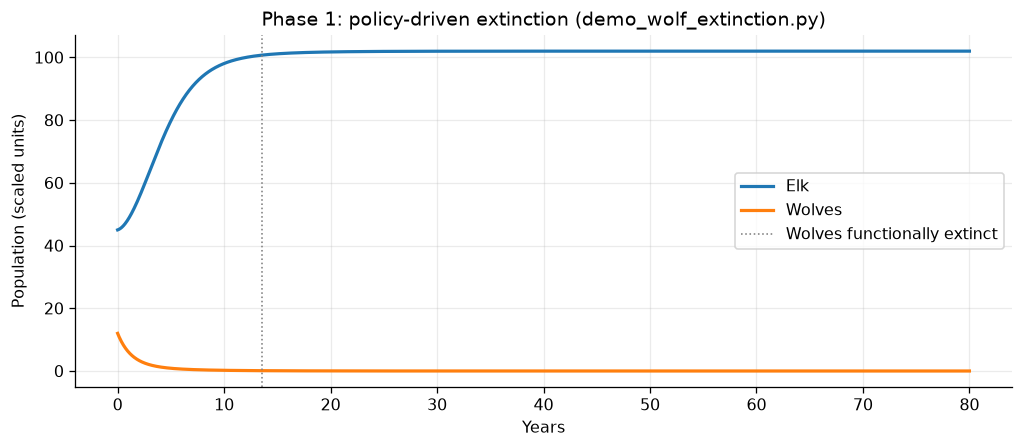

In [2]:
extinction_model = make_wolf_elk_model(**EXTINCTION_PARAMS)
sol_ext = extinction_model.solve(EXTINCTION_Y0, EXTINCTION_T_SPAN, n_points=1601)

E_end, W_end = sol_ext.y[:, -1]
t_gone = sol_ext.t[np.argmax(sol_ext.y[1] < EXTINCT_BELOW)]
pe = extinction_model.parameters
E_wolf_free = pe["KF"] * (1 - pe["hE"] / pe["r"])

print(f"Extinction run: start (E, W) = {EXTINCTION_Y0}, parameters {EXTINCTION_PARAMS}")
print(f"Wolves functionally extinct (W < {EXTINCT_BELOW}) after {t_gone:.1f} years")
print(f"End state after {EXTINCTION_T_SPAN[1]:.0f} years: elk = {E_end:.2f}, wolves = {W_end:.1e}")
print(f"Elk end at {E_end / pe['KF']:.0%} of carrying capacity KF = {pe['KF']:.0f} "
      f"(wolf-free equilibrium KF(1 - hE/r) = {E_wolf_free:.2f})")

y0 = [E_end, 0.0]   # starting point of the reintroduction model
print(f"\nReintroduction starts from y0 = (elk {y0[0]:.2f}, wolves {y0[1]:.0f})")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(sol_ext.t, sol_ext.y[0], lw=2, label="Elk")
ax.plot(sol_ext.t, sol_ext.y[1], lw=2, label="Wolves")
ax.axvline(t_gone, color="gray", ls=":", lw=1, label="Wolves functionally extinct")
ax.set(xlabel="Years", ylabel="Population (scaled units)",
       title="Phase 1: policy-driven extinction (demo_wolf_extinction.py)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

## 5. Parameters

The reintroduction model inherits **every** biological and human-pressure parameter from the extinction run (habitat $K_F$, elk hunting $h_E$, and extinction-era wolf killing $h_W + p_F$), so the only things that change are the release and the protection policy. Time $t = 0$ is the end of the extinction run.

In [3]:
REINTRO_PARAMS = {
    **extinction_model.parameters,   # r, a, h, c, b, m, KF, hE, hW, pF from the extinction run
    # --- reintroduction ---
    "t_release":     5,     # first release, years after the end of the extinction run
    "release_width": 0.25,  # length of each release window, years (~3 months)
    "release_total": 1.5,   # wolf units per release (~15 wolves; 1995: 14, 1996: 17)
    "n_releases":    2,     # number of releases (1995 and 1996)
    "release_gap":   1,     # years between releases
    # --- protection ---
    "t_protect":     5,     # protection starts with the first release
    "phi_protected": 0.2,   # 10(j): most human-caused deaths stop, problem wolves still removed
    "t_delist":      np.inf,  # when protection ends (np.inf = never)
    "phi_delisted":  0.5,   # regulated hunting after delisting (only used if t_delist is finite)
    # --- Allee effect ---
    "A":             0.0,   # recruitment halved at W = A; 0 = no Allee effect
}
for k in ("KF", "hE", "hW", "pF"):
    print(f"{k:3s} = {REINTRO_PARAMS[k]:<6} (inherited from the extinction run)")

KF  = 110.0  (inherited from the extinction run)
hE  = 0.04   (inherited from the extinction run)
hW  = 0.35   (inherited from the extinction run)
pF  = 0.45   (inherited from the extinction run)


## 6. Policy functions: $R(t)$ and $\phi(t)$

$R(t)$ is a set of rectangular pulses whose integral over each window equals `release_total`. $\phi(t)$ is a step function: unprotected, then protected, then delisted.

In [4]:
def release_rate(t, p):
    """Wolves added per unit time by reintroduction, R(t).

    There are n_releases events. Event k starts at t_release + k*release_gap and
    lasts release_width. During an event the rate is constant at
    release_total / release_width, so each event adds exactly release_total wolves.
    """
    width, gap, n = p["release_width"], p["release_gap"], int(p["n_releases"])
    if width <= 0 or (n > 1 and width > gap):
        raise ValueError("Need 0 < release_width <= release_gap")
    elapsed = t - p["t_release"]
    if elapsed < 0:
        return 0.0                                # before the first release
    k = int(elapsed // gap) if n > 1 else 0       # which release window t could be in
    if k >= n:
        return 0.0                                # after the last release
    if elapsed - k * gap < width:
        return p["release_total"] / width         # inside window k
    return 0.0                                    # between windows


def protection_factor(t, p):
    """phi(t): fraction of human-caused wolf deaths still allowed.

    1 = no protection, 0 = full protection. Three phases:
    unprotected -> protected (from t_protect) -> delisted (from t_delist).
    """
    if t < p["t_protect"]:
        return 1.0
    if t < p["t_delist"]:
        return p["phi_protected"]
    return p["phi_delisted"]


def policy_breakpoints(p, t_span):
    """Times where R(t) or phi(t) jump. The solver restarts at each one so it never steps over a release."""
    times = [p["t_protect"], p["t_delist"]]
    for k in range(int(p["n_releases"])):
        start = p["t_release"] + k * p["release_gap"]
        times += [start, start + p["release_width"]]
    inside = [t for t in times if np.isfinite(t) and t_span[0] < t < t_span[1]]
    return [t_span[0], *sorted(set(inside)), t_span[1]]

Total released: 3.000 units (expected 3.0) = about 30 wolves


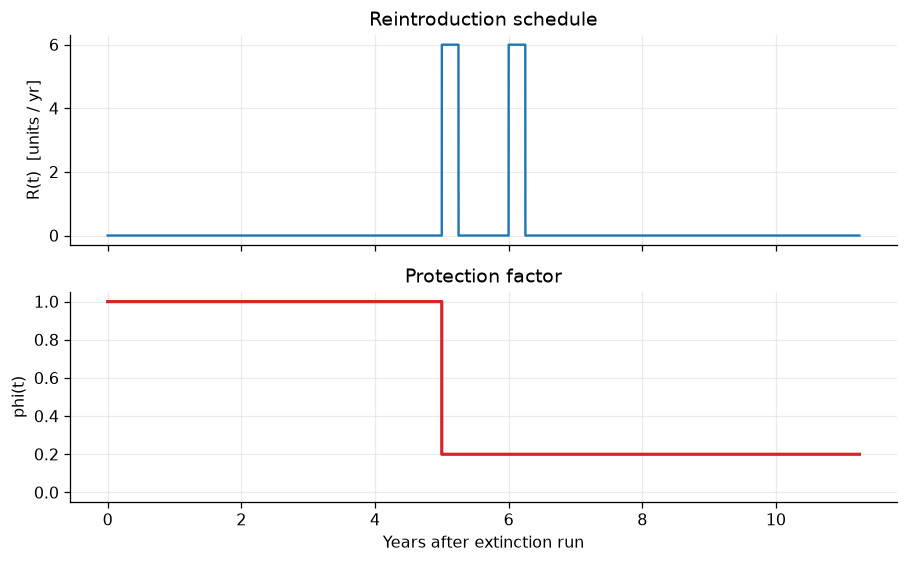

In [5]:
# Sanity check: integrate R(t) and plot both policy functions
p = REINTRO_PARAMS
t_end = p["t_release"] + (p["n_releases"] - 1) * p["release_gap"] + p["release_width"] + 5
t_check = np.linspace(0, t_end, 200_001)
R_vals = np.array([release_rate(t, p) for t in t_check])
phi_vals = np.array([protection_factor(t, p) for t in t_check])

released = np.trapezoid(R_vals, t_check)
expected = p["release_total"] * p["n_releases"]
print(f"Total released: {released:.3f} units (expected {expected}) = about {released * WOLF_UNIT:.0f} wolves")
assert abs(released - expected) < 0.01 * expected

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
ax1.plot(t_check, R_vals, lw=1.5)
ax1.set(ylabel="R(t)  [units / yr]", title="Reintroduction schedule")
ax2.step(t_check, phi_vals, where="post", color="tab:red", lw=2)
ax2.set(xlabel="Years after extinction run", ylabel="phi(t)", ylim=(-0.05, 1.05), title="Protection factor")
for ax in (ax1, ax2):
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## 7. Right-hand side and the full timeline

`reintroduction_rhs` reuses `wolf_elk_rhs` with the human wolf-death rates multiplied by $\phi(t)$, then adds the release and (if $A>0$) the Allee correction. `simulate` restarts the solver at every policy breakpoint, so releases are resolved exactly and runs are fast enough for parameter sweeps.

In [6]:
def reintroduction_rhs(t, y, p):
    E, W = y
    phi = protection_factor(t, p)
    rates = wolf_elk_rhs(t, y, {**p, "hW": phi * p["hW"], "pF": phi * p["pF"]})
    if p["A"] > 0:   # Allee: recruitment multiplied by W/(W+A), i.e. reduced by A/(W+A)
        predation = p["a"] * E * W / (1 + p["a"] * p["h"] * E + p["c"] * W)
        rates[1] -= p["A"] / (W + p["A"]) * p["b"] * predation
    rates[1] += release_rate(t, p)
    return rates


def make_scenario(title="Wolf reintroduction", **updates):
    """ODESystem with REINTRO_PARAMS plus overrides."""
    return ODESystem(rhs=reintroduction_rhs, state_names=("Elk", "Wolves"),
                     parameters={**REINTRO_PARAMS, **updates}, title=title)


T_SPAN = (0, 150)

def simulate(model, y0=None, t_span=T_SPAN, n_points=1501):
    """Integrate piecewise between policy breakpoints; returns an object with .t and .y."""
    y = np.asarray(y0 if y0 is not None else globals()["y0"], dtype=float)
    t_eval = np.linspace(*t_span, n_points)
    breaks = policy_breakpoints(model.parameters, t_span)
    ys = []
    for i, (a, b) in enumerate(zip(breaks[:-1], breaks[1:])):
        last = i == len(breaks) - 2
        mask = (t_eval >= a) & ((t_eval <= b) if last else (t_eval < b))
        seg = solve_ivp(model.evaluate, (a, b), y, rtol=1e-8, atol=1e-10, dense_output=True)
        if not seg.success:
            raise RuntimeError(seg.message)
        if mask.any():   # a short release window may contain no output times
            ys.append(seg.sol(t_eval[mask]))
        y = np.maximum(seg.sol(b), 0.0)
    return SimpleNamespace(t=t_eval, y=np.hstack(ys))


def final_state(model, y0=None, t_span=(0, 300)):
    """Long-run (E, W), treating W below EXTINCT_BELOW as 0."""
    E, W = simulate(model, y0, t_span, n_points=301).y[:, -1]
    return E, (W if W >= EXTINCT_BELOW else 0.0)


def recovery_time(sol, p, target, frac=0.9):
    """Years after the first release until wolves first reach frac * target (nan if never)."""
    hit = np.flatnonzero((sol.t >= p["t_release"]) & (sol.y[1] >= frac * target))
    return sol.t[hit[0]] - p["t_release"] if hit.size else np.nan

Final populations: elk = 54.8, wolves = 10.65 (about 107 real wolves)
Wolves reach 90% of that 5.7 years after the first release


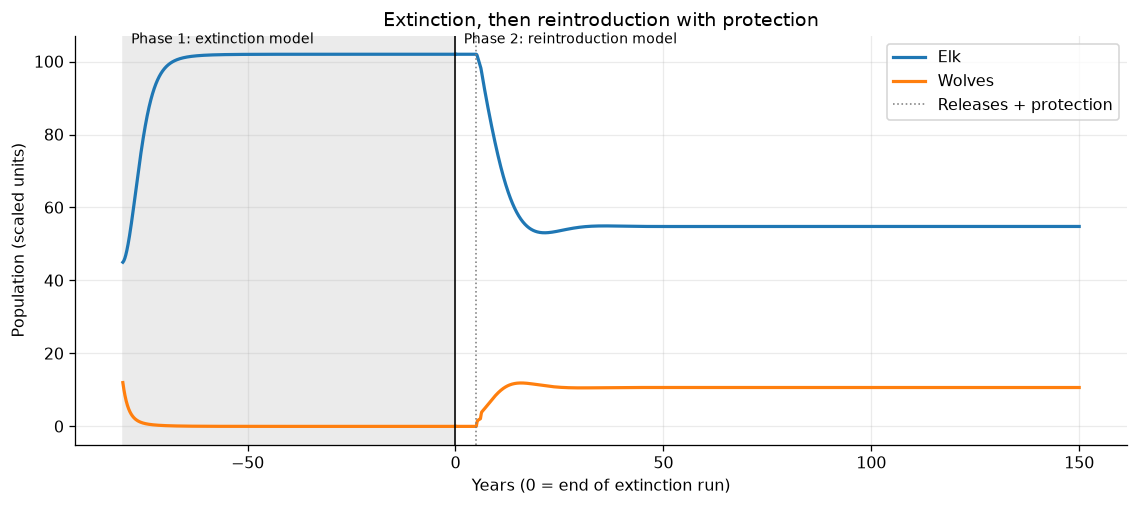

In [7]:
model = make_scenario()
sol = simulate(model)
TARGET_W = sol.y[1, -1]   # protected equilibrium; "recovered" = 90% of this
print(f"Final populations: elk = {sol.y[0, -1]:.1f}, wolves = {TARGET_W:.2f} "
      f"(about {TARGET_W * WOLF_UNIT:.0f} real wolves)")
print(f"Wolves reach 90% of that {recovery_time(sol, REINTRO_PARAMS, TARGET_W):.1f} years after the first release")

# One timeline: extinction run (negative years) followed by the reintroduction run
t_ext = sol_ext.t - EXTINCTION_T_SPAN[1]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(t_ext, sol_ext.y[0], color="tab:blue", lw=2, label="Elk")
ax.plot(t_ext, sol_ext.y[1], color="tab:orange", lw=2, label="Wolves")
ax.plot(sol.t, sol.y[0], color="tab:blue", lw=2)
ax.plot(sol.t, sol.y[1], color="tab:orange", lw=2)
ax.axvspan(t_ext[0], 0, color="0.92", zorder=0)
ax.axvline(0, color="black", lw=1)
ax.text(t_ext[0] + 2, 108, "Phase 1: extinction model", fontsize=9, va="top")
ax.text(2, 108, "Phase 2: reintroduction model", fontsize=9, va="top")
ax.axvline(REINTRO_PARAMS["t_release"], color="gray", ls=":", lw=1, label="Releases + protection")
ax.set(xlabel="Years (0 = end of extinction run)", ylabel="Population (scaled units)",
       title="Extinction, then reintroduction with protection")
ax.grid(alpha=0.25)
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig("reintroduction_timeline.png", dpi=150, bbox_inches="tight")
plt.show()

### Zoom: the release years

The full timeline squeezes the releases into a few pixels. Here are the first 15 years after the first release. Shaded bars are the two release windows. The dashed line is what the wolf count would be if **only** the released wolves counted (no births, no deaths), so the gap between it and the actual wolf curve is the population's own growth.

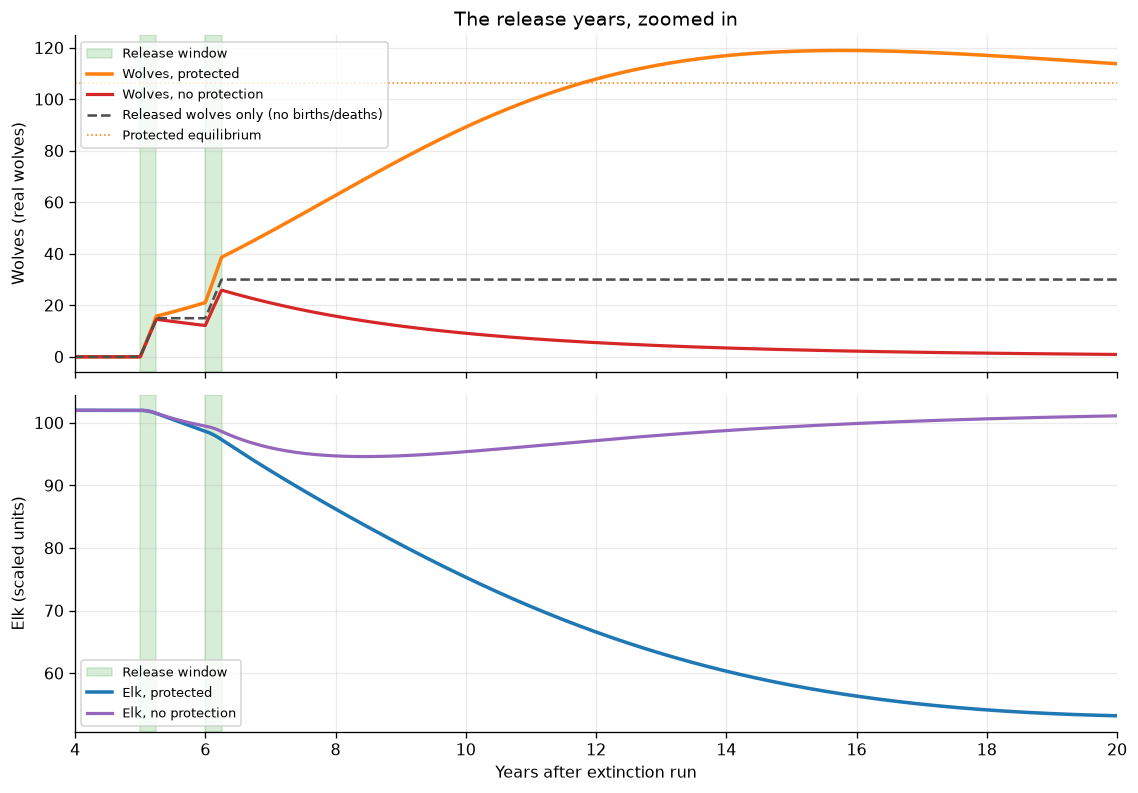

 years after 1st release  protected  unprotected  released only  elk (prot.)
                    0.25       15.8         14.6           15.0        101.5
                    1.25       38.6         25.8           29.9         97.3
                    2.00       48.6         20.9           30.0         92.3
                    3.00       62.7         15.8           30.0         86.2
                    5.00       89.2          9.1           30.0         75.3
                    8.00      113.5          4.3           30.0         63.2
                   10.00      118.6          2.7           30.0         58.1
                   15.00      113.8          0.9           30.0         53.2


In [8]:
p = REINTRO_PARAMS
release_windows = [(p["t_release"] + k * p["release_gap"],
                    p["t_release"] + k * p["release_gap"] + p["release_width"])
                   for k in range(int(p["n_releases"]))]
t0, t1 = p["t_release"] - 1, p["t_release"] + 15
zoom_span = (0, t1 + 1)

sol_zoom = simulate(model, t_span=zoom_span, n_points=4001)                      # release + protection
sol_zoom_unprot = simulate(make_scenario(phi_protected=1.0), t_span=zoom_span, n_points=4001)
released_only = np.array([sum(np.clip(t - a, 0, b - a) for a, b in release_windows) for t in sol_zoom.t]) \
                * p["release_total"] / p["release_width"]

fig, (ax_w, ax_e) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax in (ax_w, ax_e):
    for k, (a, b) in enumerate(release_windows):
        ax.axvspan(a, b, color="tab:green", alpha=0.18, label="Release window" if k == 0 else None)
    ax.grid(alpha=0.25)
ax_w.plot(sol_zoom.t, sol_zoom.y[1] * WOLF_UNIT, lw=2.2, color="tab:orange", label="Wolves, protected")
ax_w.plot(sol_zoom_unprot.t, sol_zoom_unprot.y[1] * WOLF_UNIT, lw=2, color="tab:red", label="Wolves, no protection")
ax_w.plot(sol_zoom.t, released_only * WOLF_UNIT, lw=1.6, ls="--", color="0.3", label="Released wolves only (no births/deaths)")
ax_w.axhline(TARGET_W * WOLF_UNIT, color="tab:orange", ls=":", lw=1, label="Protected equilibrium")
ax_w.set(ylabel="Wolves (real wolves)", title="The release years, zoomed in")
ax_w.legend(fontsize=8, loc="upper left")
ax_e.plot(sol_zoom.t, sol_zoom.y[0], lw=2.2, color="tab:blue", label="Elk, protected")
ax_e.plot(sol_zoom_unprot.t, sol_zoom_unprot.y[0], lw=2, color="tab:purple", label="Elk, no protection")
ax_e.set(xlabel="Years after extinction run", ylabel="Elk (scaled units)", xlim=(t0, t1))
ax_e.legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

def wolves_at(s, t):
    return np.interp(t, s.t, s.y[1]) * WOLF_UNIT
print(f"{'years after 1st release':>24s} {'protected':>10s} {'unprotected':>12s} {'released only':>14s} {'elk (prot.)':>12s}")
for dt in (0.25, 1.25, 2, 3, 5, 8, 10, 15):
    t = p["t_release"] + dt
    print(f"{dt:24.2f} {wolves_at(sol_zoom, t):10.1f} {wolves_at(sol_zoom_unprot, t):12.1f} "
          f"{np.interp(t, sol_zoom.t, released_only) * WOLF_UNIT:14.1f} {np.interp(t, sol_zoom.t, sol_zoom.y[0]):12.1f}")

**What the zoom shows.**

- **The releases are the two steps of about 15 wolves.** Between them, the protected wolves are already growing (about 16 → 21), while unprotected wolves are already shrinking (15 → 12).
- **Births do most of the work.** Only 30 wolves are ever released, but protected wolves reach about 49 one year after the second release, 89 five years after the first, and peak near 119 around year 11. Roughly three quarters of the recovered population comes from reproduction, not the release.
- **Without protection the same 30 wolves fade away.** They peak at about 26 right after the second release, fall to about 9 by year 5, and are below one real wolf by year 15.
- **Elk respond with a lag.** They barely move during the releases (102 → 97 in the first year) and do most of their decline between years 2 and 10, as the wolf population builds. Without protection, elk dip only to about 95 and then recover.

## 8. Baseline: protection alone, no release

With $R \equiv 0$ and $W(0) = 0$, the invariance from Section 2 says wolves stay at zero no matter how strong the protection is, and elk stay at their wolf-free equilibrium $K_F(1 - h_E/r)$.

In [9]:
baseline = make_scenario("No reintroduction", n_releases=0)
sol_base = simulate(baseline)
print(f"Max wolves at any time: {sol_base.y[1].max():.2e}")
print(f"Elk start {sol_base.y[0, 0]:.2f}, end {sol_base.y[0, -1]:.2f} "
      f"(wolf-free equilibrium {E_wolf_free:.2f})")

Max wolves at any time: 0.00e+00
Elk start 102.00, end 102.00 (wolf-free equilibrium 102.00)


## 9. Scenario comparison

All five scenarios start from the end of the extinction run. Scenario 4 delists 16 years after the first release (like 1995 → 2011) to regulated hunting ($\phi = 0.5$); scenario 5 delists to extinction-era pressure ($\phi = 1$).

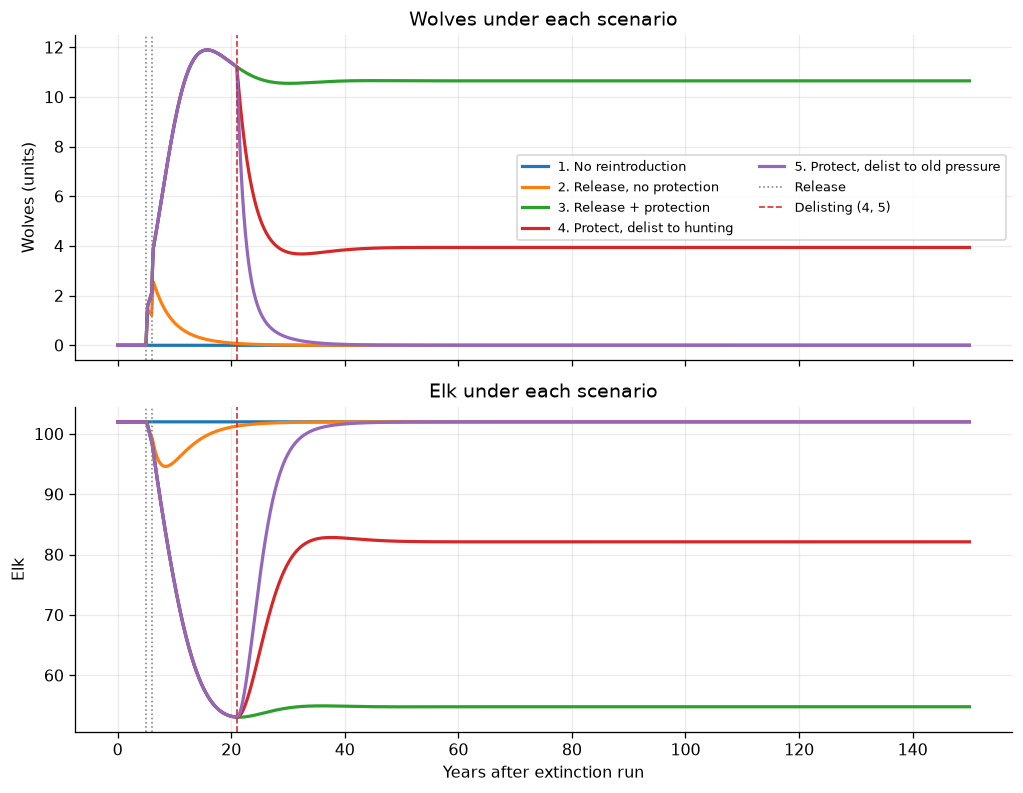

scenario                             final elk  final wolves  peak wolves yrs to 90%
1. No reintroduction                     102.0          0.00         0.00      never
2. Release, no protection                102.0          0.00         2.55      never
3. Release + protection                   54.8         10.65        11.90        5.7
4. Protect, delist to hunting             82.1          3.94        11.90        5.7
5. Protect, delist to old pressure       102.0          0.00        11.90        5.7


In [10]:
t_delist_demo = REINTRO_PARAMS["t_release"] + 16
scenarios = {
    "1. No reintroduction":              make_scenario(n_releases=0),
    "2. Release, no protection":         make_scenario(phi_protected=1.0),
    "3. Release + protection":           make_scenario(),
    "4. Protect, delist to hunting":     make_scenario(t_delist=t_delist_demo, phi_delisted=0.5),
    "5. Protect, delist to old pressure": make_scenario(t_delist=t_delist_demo, phi_delisted=1.0),
}
results = {name: simulate(m) for name, m in scenarios.items()}

p = REINTRO_PARAMS
release_times = [p["t_release"] + k * p["release_gap"] for k in range(int(p["n_releases"]))]

fig, (ax_w, ax_e) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for name, s in results.items():
    ax_w.plot(s.t, s.y[1], lw=2, label=name)
    ax_e.plot(s.t, s.y[0], lw=2, label=name)
for ax in (ax_w, ax_e):
    for k, tr in enumerate(release_times):
        ax.axvline(tr, color="gray", ls=":", lw=1, label="Release" if (k == 0 and ax is ax_w) else None)
    ax.axvline(t_delist_demo, color="tab:red", ls="--", lw=1,
               label="Delisting (4, 5)" if ax is ax_w else None)
    ax.grid(alpha=0.25)
ax_w.set(ylabel="Wolves (units)", title="Wolves under each scenario")
ax_e.set(xlabel="Years after extinction run", ylabel="Elk", title="Elk under each scenario")
ax_w.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

print(f"{'scenario':36s} {'final elk':>9s} {'final wolves':>13s} {'peak wolves':>12s} {'yrs to 90%':>10s}")
for name, s in results.items():
    rt = recovery_time(s, p, TARGET_W)
    print(f"{name:36s} {s.y[0, -1]:9.1f} {s.y[1, -1]:13.2f} {s.y[1].max():12.2f} "
          f"{'never' if np.isnan(rt) else f'{rt:.1f}':>10s}")

**What the scenarios show.**

- **Only the protected scenarios recover.** Without protection (scenario 2), the ~30 released wolves peak at about 2.6 units (~25 wolves) and then die out. Extinction-era human-caused deaths ($0.8$/yr) are larger than the wolves' best possible net growth rate (about $0.6$/yr), so no release can survive them.
- **With protection (scenario 3), wolves recover in about 6 years.** They reach 90% of their equilibrium (about 107 real wolves) roughly 5.7 years after the first release, briefly overshoot to about 119, and settle. For comparison, Yellowstone's wolves passed 100 within about five years of the 1995 release.
- **Elk are roughly halved.** They fall from 102 to about 55. This is the top-down effect of predation, and the reason wolves matter for willow, aspen, and the rest of the ecosystem.
- **Delisting is not fatal by itself, but the policy after it decides everything.** With regulated hunting ($\phi = 0.5$, scenario 4), wolves drop to about 39 real wolves and elk rebound to about 82. If pressure returns to extinction-era levels (scenario 5), wolves are lost again and elk return to 102, the same end state as the extinction model.

## 10. Long-term behaviour after the releases

After the last release, $R = 0$ and $\phi$ is constant, so the system is autonomous and we can find and classify its equilibria.

**Analytical persistence condition.** With no wolves, elk sit at $E_0 = K_F(1 - h_E/r)$. A small wolf population at that point grows if and only if its per-capita growth rate is positive:

$$
\frac{b\,aE_0}{1 + ahE_0} - m - \phi\,(h_W + p_F) > 0
\quad\Longleftrightarrow\quad
\phi < \phi_c = \frac{\dfrac{b\,aE_0}{1 + ahE_0} - m}{h_W + p_F}.
$$

Below $\phi_c$ the wolf-free point is a saddle and a coexistence equilibrium $(E^*, W^*)$ with $W^* > 0$ exists; above $\phi_c$ the wolf-free point is stable and wolves always die out (with $A = 0$).

Max wolf net growth at E0 = 102.0: 0.598 /yr
Critical protection factor phi_c = 0.747  (wolves persist only if phi < 0.747, i.e. at least 25% of human-caused deaths stop)

Protected (phi = 0.2)
  E =    0.0, W =  0.00  ->  unstable (saddle-type)           eigenvalues: +0.5100+0.0000i, -0.3400+0.0000i
  E =   54.8, W = 10.65  ->  locally asymptotically stable    eigenvalues: -0.1714+0.2158i, -0.1714-0.2158i
  E =  102.0, W =  0.00  ->  unstable (saddle-type)           eigenvalues: -0.5100+0.0000i, +0.4375+0.0000i

Delisted to hunting (phi = 0.5)
  E =    0.0, W =  0.00  ->  unstable (saddle-type)           eigenvalues: +0.5100+0.0000i, -0.5800+0.0000i
  E =   82.1, W =  3.94  ->  locally asymptotically stable    eigenvalues: -0.2300+0.1253i, -0.2300-0.1253i
  E =  102.0, W =  0.00  ->  unstable (saddle-type)           eigenvalues: -0.5100+0.0000i, +0.1975+0.0000i

Unprotected (phi = 1)
  E =    0.0, W =  0.00  ->  unstable (saddle-type)           eigenvalues: +0.5100+0.0000i, -0.9800+0.

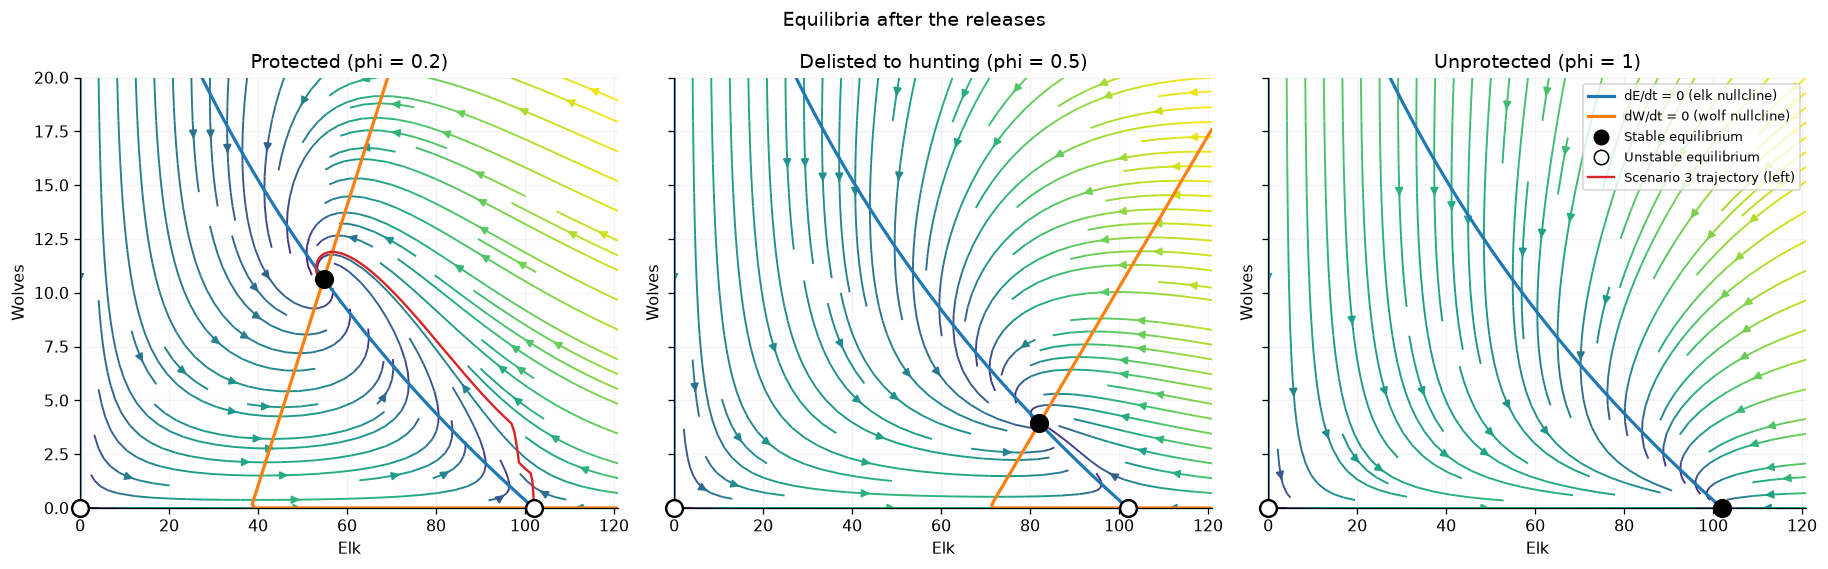

In [11]:
p = REINTRO_PARAMS
E0_star = p["KF"] * (1 - p["hE"] / p["r"])
max_net_growth = p["b"] * p["a"] * E0_star / (1 + p["a"] * p["h"] * E0_star) - p["m"]
phi_c = max_net_growth / (p["hW"] + p["pF"])
print(f"Max wolf net growth at E0 = {E0_star:.1f}: {max_net_growth:.3f} /yr")
print(f"Critical protection factor phi_c = {phi_c:.3f}  "
      f"(wolves persist only if phi < {phi_c:.3f}, i.e. at least {1 - phi_c:.0%} of human-caused deaths stop)\n")

def post_release_model(phi, title):
    return make_scenario(title, n_releases=0, t_protect=-np.inf, t_delist=np.inf, phi_protected=phi)

post_models = {
    f"Protected (phi = {p['phi_protected']})": post_release_model(p["phi_protected"], "Protected"),
    f"Delisted to hunting (phi = {p['phi_delisted']})": post_release_model(p["phi_delisted"], "Delisted"),
    "Unprotected (phi = 1)": post_release_model(1.0, "Unprotected"),
}
XLIM, YLIM = (0, 1.1 * p["KF"]), (0, 20)

equilibria = {}
for name, m in post_models.items():
    print(name)
    equilibria[name] = []
    for pt in m.find_equilibria(XLIM, YLIM, starts_per_axis=9):
        info = m.stability(pt)
        ev = ", ".join(f"{z.real:+.4f}{z.imag:+.4f}i" for z in info["eigenvalues"])
        print(f"  E = {pt[0]:6.1f}, W = {pt[1]:5.2f}  ->  {info['classification']:32s} eigenvalues: {ev}")
        equilibria[name].append((pt, info["classification"]))
    print()

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, (name, m) in zip(axes, post_models.items()):
    m.plot_streamplot(XLIM, YLIM, ax=ax, density=1.0)
    X, Y, U, V = m.vector_field(XLIM, YLIM, grid=121)
    ax.contour(X, Y, U, levels=[0], colors=["tab:blue"], linewidths=2)
    ax.contour(X, Y, V, levels=[0], colors=["tab:orange"], linewidths=2)
    for pt, label in equilibria[name]:
        stable = label.startswith("locally asymptotically stable")
        ax.scatter(*pt, s=110, zorder=6, clip_on=False, edgecolors="black", linewidths=1.5,
                   facecolors="black" if stable else "white")
    ax.set_title(name)
s3 = results["3. Release + protection"]
axes[0].plot(s3.y[0], s3.y[1], color="tab:red", lw=1.5)

from matplotlib.lines import Line2D
axes[2].legend(handles=[
    Line2D([0], [0], color="tab:blue", lw=2, label="dE/dt = 0 (elk nullcline)"),
    Line2D([0], [0], color="tab:orange", lw=2, label="dW/dt = 0 (wolf nullcline)"),
    Line2D([0], [0], marker="o", ls="", mfc="black", mec="black", ms=9, label="Stable equilibrium"),
    Line2D([0], [0], marker="o", ls="", mfc="white", mec="black", ms=9, label="Unstable equilibrium"),
    Line2D([0], [0], color="tab:red", lw=1.5, label="Scenario 3 trajectory (left)"),
], fontsize=8, loc="upper right")
fig.suptitle("Equilibria after the releases")
fig.tight_layout()
plt.show()

**The numerical equilibria match the analysis.** The critical protection factor is $\phi_c \approx 0.75$:

- At $\phi = 0.2$ and $\phi = 0.5$ (both below $\phi_c$), the wolf-free point $(102, 0)$ is a **saddle** and the coexistence point is a **stable spiral**. Its complex eigenvalues explain the damped overshoot seen in Section 9.
- At $\phi = 1$ the coexistence point no longer exists and the wolf-free point is **stable**. That is the end state of the extinction model.

The positive eigenvalue at the wolf-free point is the growth rate of a small wolf population: $0.598 - 0.8\phi$. At $\phi = 0.2$ it is $0.44$/yr, so a newly released population roughly doubles every 1.6 years. That answers how a release of about 30 wolves becomes more than 100: births, not releases.

## 11. How the starting point changes the outcome

The extinction run gives one specific starting point. Here we change it in three ways:

1. **Anywhere in the phase plane.** Under protection, do trajectories from many different $(E_0, W_0)$ end in the same place?
2. **Elk numbers at release.** What if elk were lower when wolves arrived (for example, heavier elk hunting during the wolf-free years)?
3. **Release size, with and without an Allee effect.** Does the number of wolves released change the long-run outcome?
4. **A sudden addition to a stable population.** What happens if a large batch of wolves is added after the population has settled?

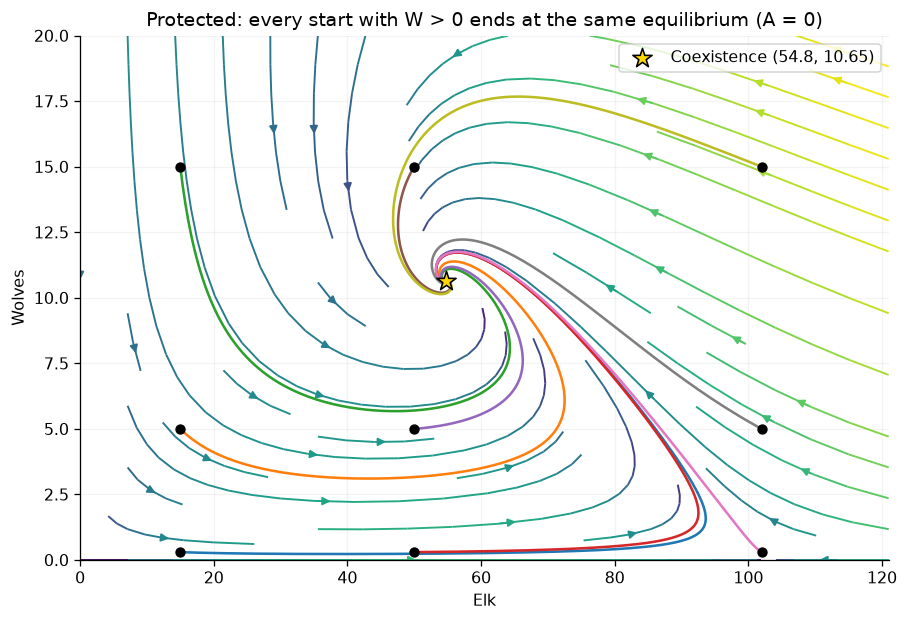

In [12]:
# 11a. Many starting points under protection, no release (wolves already present)
protected = post_release_model(REINTRO_PARAMS["phi_protected"], "Protected")
starts = [(E, W) for E in (15, 50, 102) for W in (0.3, 5, 15)]

fig, ax = plt.subplots(figsize=(8, 5.5))
protected.plot_streamplot(XLIM, YLIM, ax=ax, density=0.6)
for E0_, W0_ in starts:
    s = protected.solve((E0_, W0_), (0, 200), n_points=2001)
    ax.plot(s.y[0], s.y[1], lw=1.6)
    ax.scatter(E0_, W0_, s=30, color="black", zorder=5)
E_star, W_star = s.y[:, -1]
ax.scatter(E_star, W_star, s=160, marker="*", color="gold", edgecolors="black", zorder=6,
           label=f"Coexistence ({E_star:.1f}, {W_star:.2f})")
ax.set(title="Protected: every start with W > 0 ends at the same equilibrium (A = 0)")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig("reintroduction_phase_plane_starts.png", dpi=150, bbox_inches="tight")
plt.show()

elk at release  peak wolves  final wolves yrs to 90%
            25        11.67         10.65        6.6
            50        11.81         10.65        6.0


            75        11.86         10.65        5.8
           102        11.90         10.65        5.7


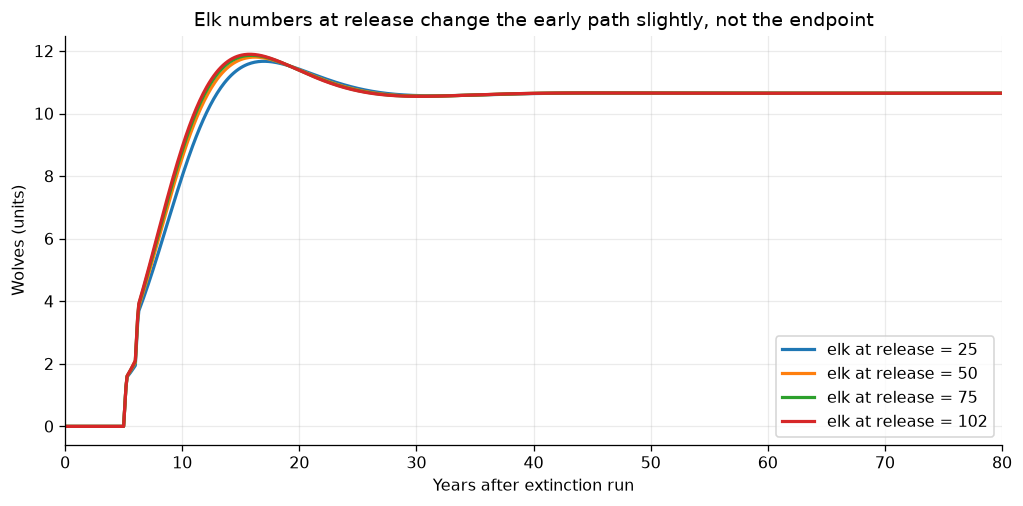

In [13]:
# 11b. Elk numbers at the moment of release
elk_starts = [25, 50, 75, E_end]
fig, ax = plt.subplots(figsize=(9, 4.5))
print(f"{'elk at release':>14s} {'peak wolves':>12s} {'final wolves':>13s} {'yrs to 90%':>10s}")
for E0_ in elk_starts:
    s = simulate(model, y0=(E0_, 0.0))
    rt = recovery_time(s, REINTRO_PARAMS, TARGET_W)
    ax.plot(s.t, s.y[1], lw=2, label=f"elk at release = {E0_:.0f}")
    print(f"{E0_:14.0f} {s.y[1].max():12.2f} {s.y[1, -1]:13.2f} {rt:10.1f}")
ax.set(xlabel="Years after extinction run", ylabel="Wolves (units)", xlim=(0, 80),
       title="Elk numbers at release change the early path slightly, not the endpoint")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

A = 0    smallest total release that recovers: 2 wolves


A = 1    smallest total release that recovers: 10 wolves


A = 1.5  smallest total release that recovers: 16 wolves


A = 2    smallest total release that recovers: 22 wolves


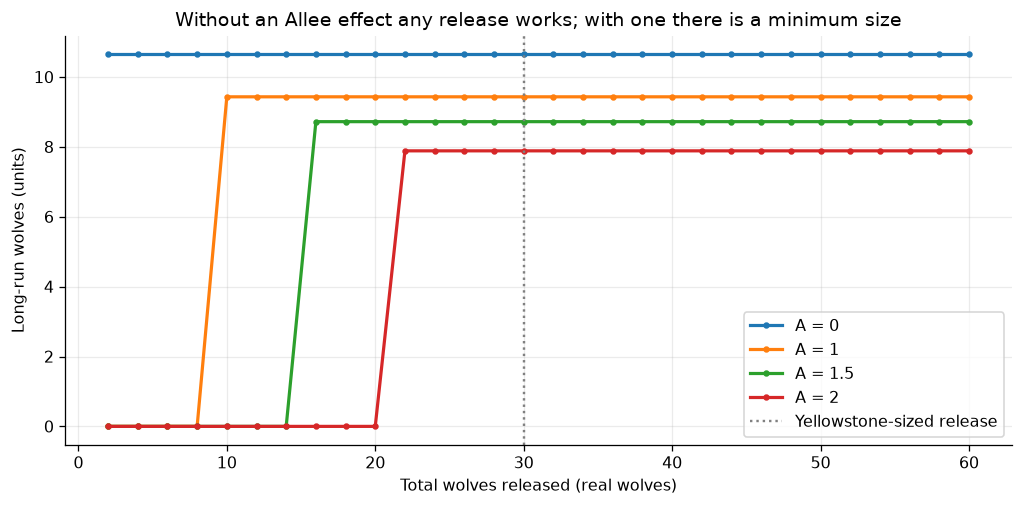

In [14]:
# 11c. Release size, with and without an Allee effect
release_sizes = np.linspace(0.1, 3.0, 30)          # wolf units per release (x2 releases)
allee_values = [0.0, 1.0, 1.5, 2.0]

fig, ax = plt.subplots(figsize=(9, 4.5))
for A in allee_values:
    finals = [final_state(make_scenario(A=A, release_total=r))[1] for r in release_sizes]
    ax.plot(2 * release_sizes * WOLF_UNIT, finals, "o-", ms=3, lw=2, label=f"A = {A:g}")
    alive = np.flatnonzero(np.array(finals) > 0)
    need = f"{2 * release_sizes[alive[0]] * WOLF_UNIT:.0f} wolves" if alive.size else "none recover"
    print(f"A = {A:<4g} smallest total release that recovers: {need}")
ax.axvline(2 * REINTRO_PARAMS["release_total"] * WOLF_UNIT, color="gray", ls=":", label="Yellowstone-sized release")
ax.set(xlabel="Total wolves released (real wolves)", ylabel="Long-run wolves (units)",
       title="Without an Allee effect any release works; with one there is a minimum size")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

Stable state at year 100: elk = 54.8, wolves = 10.65 (107 real wolves)

       added  lowest elk (yrs after)  lowest wolves (yrs after) yrs to settle       end (E, W)
      50 wlv        48.2         4.2          102.4        12.9           6.9   (54.8, 10.65)
     100 wlv        43.4         4.3           98.8        12.9          16.5   (54.8, 10.65)
     200 wlv        36.6         4.5           92.7        13.0          19.0   (54.8, 10.65)
     400 wlv        28.5         4.8           83.4        13.4          20.9   (54.8, 10.65)


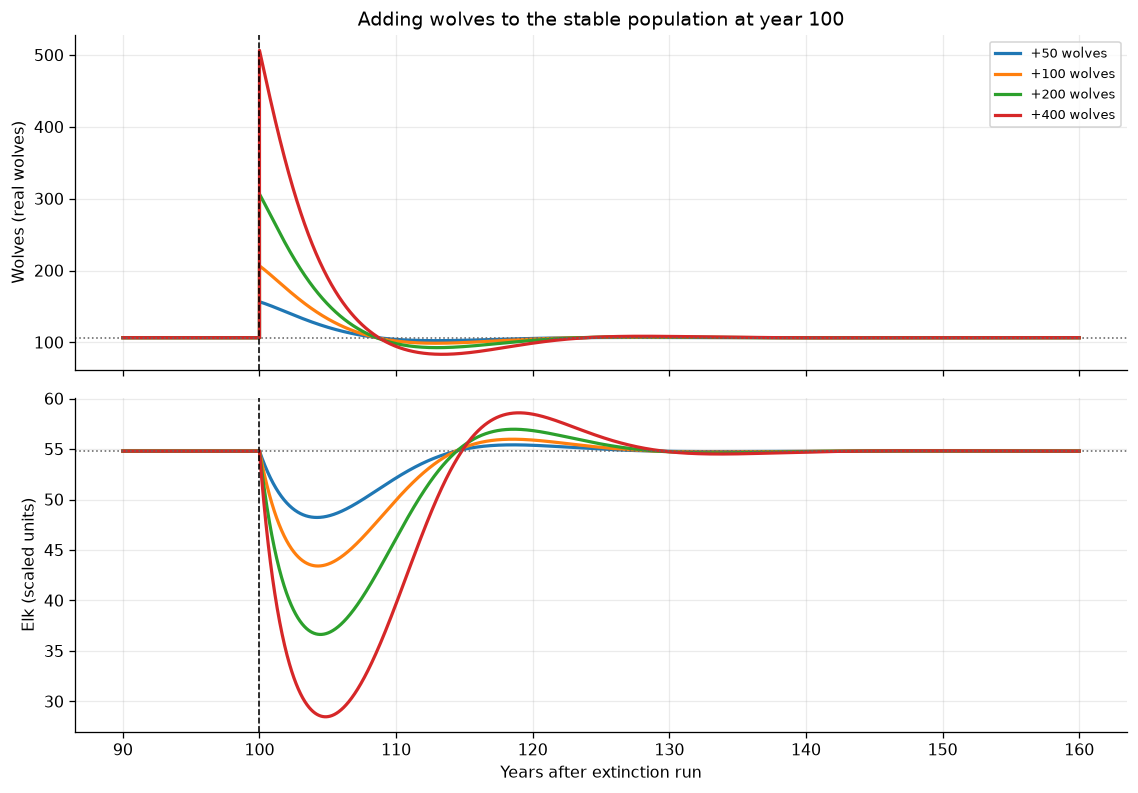

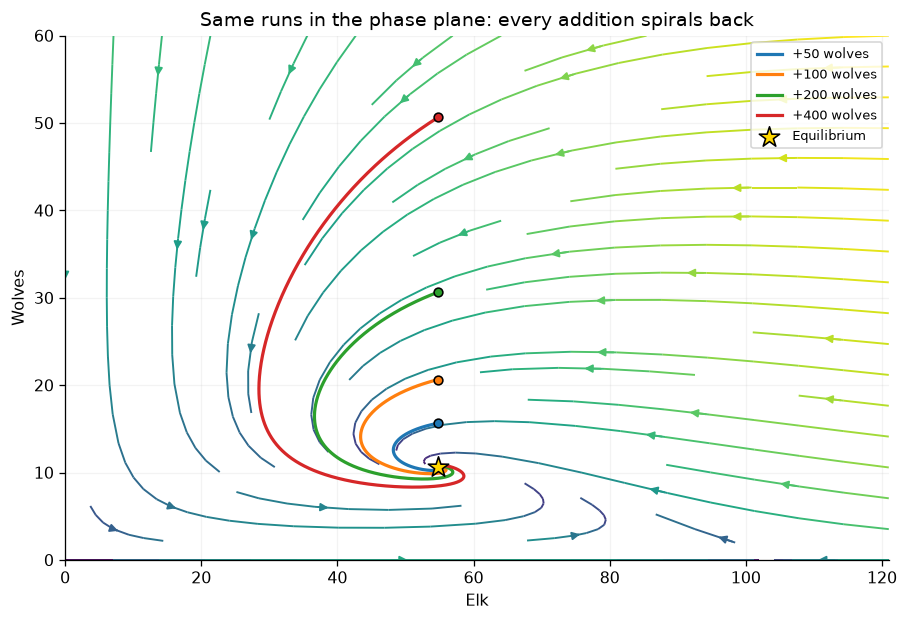

In [15]:
# 11d. Add a batch of wolves to the stable, protected population at year 100
T_ADD = 100
base_run = simulate(model, t_span=(0, T_ADD), n_points=1001)
E_stable, W_stable = base_run.y[:, -1]
additions = [5, 10, 20, 40]          # wolf units added at once (x10 = real wolves)
after_span = (T_ADD, T_ADD + 60)

fig, (ax_w, ax_e) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
fig2, ax_ph = plt.subplots(figsize=(8, 5.5))
protected.plot_streamplot((0, 1.1 * REINTRO_PARAMS["KF"]), (0, 60), ax=ax_ph, density=0.6)

print(f"Stable state at year {T_ADD}: elk = {E_stable:.1f}, wolves = {W_stable:.2f} ({W_stable * WOLF_UNIT:.0f} real wolves)\n")
print(f"{'added':>12s} {'lowest elk':>11s} {'(yrs after)':>11s} {'lowest wolves':>14s} {'(yrs after)':>11s} "
      f"{'yrs to settle':>13s} {'end (E, W)':>16s}")
for add in additions:
    s = simulate(model, y0=(E_stable, W_stable + add), t_span=after_span, n_points=3001)
    keep = base_run.t >= T_ADD - 10
    t = np.concatenate([base_run.t[keep], s.t])
    W = np.concatenate([base_run.y[1][keep], s.y[1]])
    E = np.concatenate([base_run.y[0][keep], s.y[0]])
    label = f"+{add * WOLF_UNIT} wolves"
    line, = ax_w.plot(t, W * WOLF_UNIT, lw=2, label=label)
    ax_e.plot(t, E, lw=2, color=line.get_color(), label=label)
    ax_ph.plot(s.y[0], s.y[1], lw=2, color=line.get_color(), label=label)
    ax_ph.scatter(s.y[0, 0], s.y[1, 0], s=30, color=line.get_color(), edgecolors="black", zorder=5)

    iE, iW = s.y[0].argmin(), s.y[1].argmin()
    off = np.abs(s.y[1] - W_stable) > 0.05 * W_stable                 # more than 5% away from equilibrium
    settle = s.t[np.flatnonzero(off)[-1]] - T_ADD if off.any() else 0.0
    print(f"{add * WOLF_UNIT:>8d} wlv {s.y[0, iE]:11.1f} {s.t[iE] - T_ADD:11.1f} {s.y[1, iW] * WOLF_UNIT:14.1f} "
          f"{s.t[iW] - T_ADD:11.1f} {settle:13.1f}   ({s.y[0, -1]:.1f}, {s.y[1, -1]:.2f})")

for ax in (ax_w, ax_e):
    ax.axvline(T_ADD, color="black", ls="--", lw=1)
    ax.grid(alpha=0.25)
ax_w.axhline(W_stable * WOLF_UNIT, color="0.4", ls=":", lw=1)
ax_e.axhline(E_stable, color="0.4", ls=":", lw=1)
ax_w.set(ylabel="Wolves (real wolves)", title=f"Adding wolves to the stable population at year {T_ADD}")
ax_e.set(xlabel="Years after extinction run", ylabel="Elk (scaled units)")
ax_w.legend(fontsize=8)
fig.tight_layout()

ax_ph.scatter(E_stable, W_stable, s=180, marker="*", color="gold", edgecolors="black", zorder=6, label="Equilibrium")
ax_ph.set(title="Same runs in the phase plane: every addition spirals back")
ax_ph.legend(fontsize=8, loc="upper right")
fig2.tight_layout()
plt.show()

**What the starting point changes.**

- **The endpoint does not depend on the starting point** (11a). Without an Allee effect, the coexistence equilibrium attracts every state with $W > 0$, so all starting points end in the same place. Only the path (how big the spiral is, how long it takes) differs.
- **Elk numbers at release barely matter** (11b). Going from 25 to 102 elk at the moment of release changes the recovery time only from about 6.6 to 5.7 years, and the endpoint is identical. Elk regrow quickly ($r = 0.55$/yr) while the wolf population is still small, so the wolves see similar prey either way. Starting from the extinction model's near-capacity elk gives the fastest recovery, but not by much.
- **Release size matters only with an Allee effect** (11c). With $A = 0$, even the smallest release tested (2 wolves) eventually recovers. With $A = 1$, $1.5$, or $2$ there is a minimum release of about 10, 16, or 22 wolves; below that, the wolves die out even though they are protected. The Yellowstone-sized release of about 30 clears all of these. Real small populations are also vulnerable to random bad luck, which this ODE does not include, so the true minimum is probably higher.
- **Adding wolves to a stable population does not change where it ends** (11d). Adding 50 to 400 wolves at year 100 always spirals back to the same equilibrium (about 107 wolves, 55 elk), because it is a stable spiral. The extra wolves do not last: there are not enough elk to feed them, so wolves fall back to about 107 within roughly 8 years. Along the way they eat elk down hard, to about 48 for +50 wolves and about 29 (nearly half) for +400, with the lowest point 4–5 years after the addition. Then the swing reverses: with elk depleted, wolves undershoot (down to about 83 for +400) about 13 years after the addition while elk overshoot, and the system takes 7–21 years to settle within 5% of equilibrium. Stocking extra wolves costs elk in the short run and gains nothing long term. The long-run wolf number is set by prey and human-caused mortality, not by how many wolves are put in.


## 12. How the parameter choices change the outcome

Most parameter values are not measured directly, so we check how sensitive the results are to each one.

1. **One at a time.** Raise and lower each parameter by 25% (others fixed) and record the long-run wolves and elk under protection.
2. **Protection and release size together**, with an Allee effect so that both matter.
3. **Delisting.** How much hunting can return after delisting before wolves collapse again?

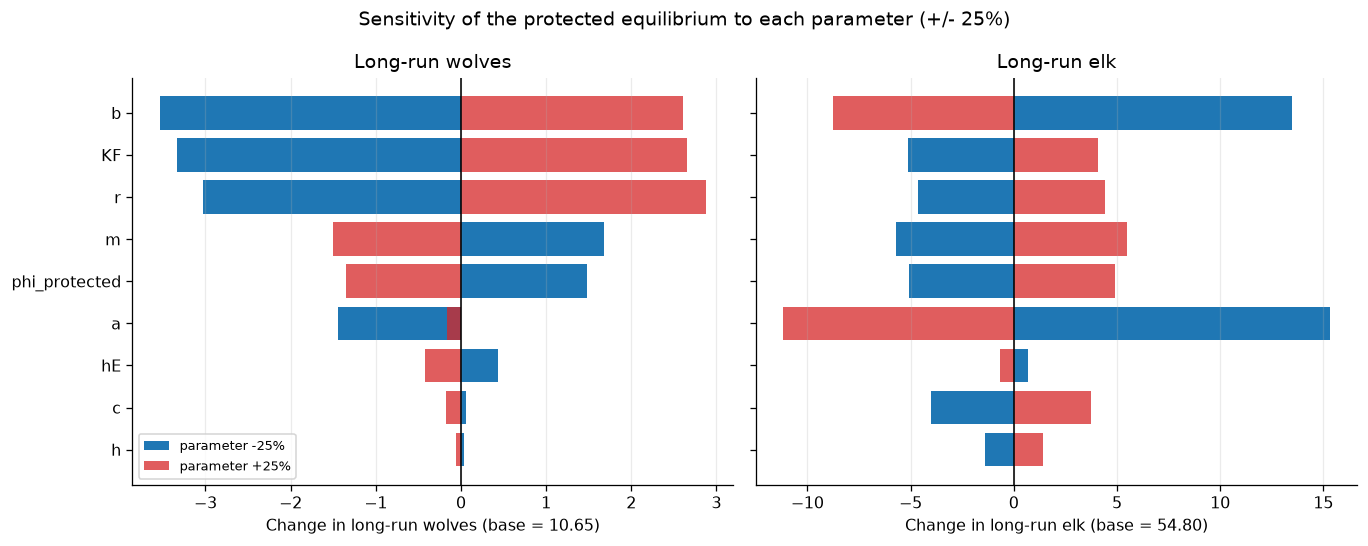

Base: elk = 54.80, wolves = 10.65
param            value  W at -25%  W at +25%  E at -25%  E at +25%
b                0.280       7.11      13.26       68.3       46.1
KF             110.000       7.32      13.31       49.7       58.9
r                0.550       7.62      13.53       50.1       59.2
m                0.180      12.33       9.14       49.1       60.3
phi_protected    0.200      12.13       9.30       49.7       59.7
a                0.035       9.21      10.49       70.1       43.6
hE               0.040      11.08      10.22       55.5       54.1
c                0.040      10.71      10.48       50.8       58.6
h                0.080      10.69      10.60       53.4       56.2


In [16]:
# 12a. One-at-a-time sensitivity (+/- 25%)
base_E, base_W = final_state(model)
names = ["r", "a", "h", "c", "b", "m", "KF", "hE", "phi_protected"]
rows = []
for k in names:
    lo = final_state(make_scenario(**{k: 0.75 * REINTRO_PARAMS[k]}))
    hi = final_state(make_scenario(**{k: 1.25 * REINTRO_PARAMS[k]}))
    rows.append((k, lo, hi))
rows.sort(key=lambda r: max(abs(r[1][1] - base_W), abs(r[2][1] - base_W)))

fig, (ax_w, ax_e) = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
y = np.arange(len(rows))
for ax, idx, base, label in ((ax_w, 1, base_W, "wolves"), (ax_e, 0, base_E, "elk")):
    lo = np.array([r[1][idx] for r in rows]) - base
    hi = np.array([r[2][idx] for r in rows]) - base
    ax.barh(y, lo, color="tab:blue", label="parameter -25%")
    ax.barh(y, hi, color="tab:red", alpha=0.75, label="parameter +25%")
    ax.axvline(0, color="black", lw=1)
    ax.set(xlabel=f"Change in long-run {label} (base = {base:.2f})", title=f"Long-run {label}")
    ax.grid(alpha=0.25, axis="x")
ax_w.set_yticks(y, [r[0] for r in rows])
ax_w.legend(fontsize=8)
fig.suptitle("Sensitivity of the protected equilibrium to each parameter (+/- 25%)")
fig.tight_layout()
plt.show()

print(f"Base: elk = {base_E:.2f}, wolves = {base_W:.2f}")
print(f"{'param':14s} {'value':>7s} {'W at -25%':>10s} {'W at +25%':>10s} {'E at -25%':>10s} {'E at +25%':>10s}")
for k, lo, hi in reversed(rows):
    print(f"{k:14s} {REINTRO_PARAMS[k]:7.3f} {lo[1]:10.2f} {hi[1]:10.2f} {lo[0]:10.1f} {hi[0]:10.1f}")

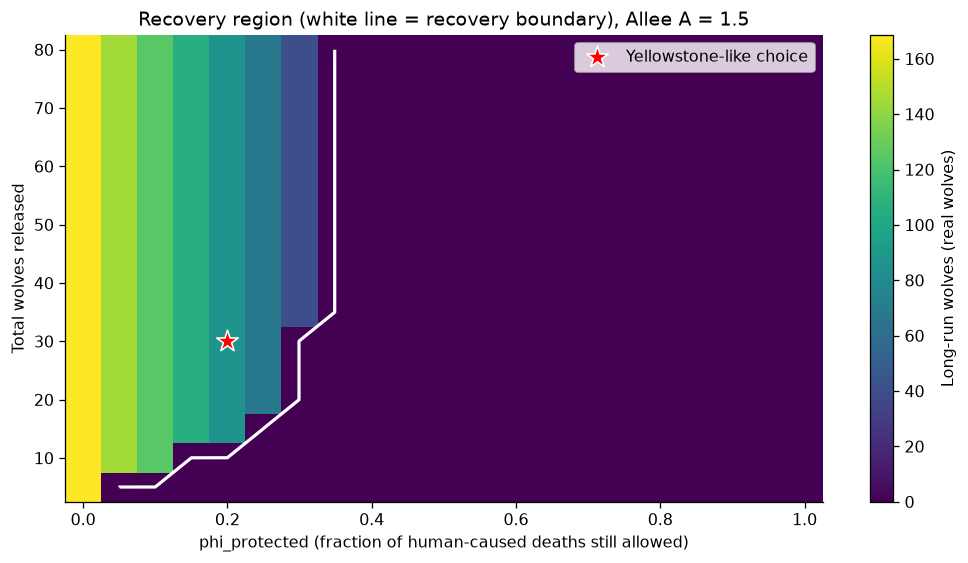

phi_c with A = 0 (analytic): 0.747
release    5 wolves: recovers for phi up to 0.00
release   45 wolves: recovers for phi up to 0.30
release   80 wolves: recovers for phi up to 0.30


In [17]:
# 12b. Protection strength vs release size (Allee effect on, A = 1.5)
A_sweep = 1.5
phis = np.linspace(0, 1, 21)
sizes = np.linspace(0.25, 4.0, 16)
grid = np.array([[final_state(make_scenario(A=A_sweep, phi_protected=ph, release_total=r))[1]
                  for ph in phis] for r in sizes])

fig, ax = plt.subplots(figsize=(9, 5))
mesh = ax.pcolormesh(phis, 2 * sizes * WOLF_UNIT, grid * WOLF_UNIT, shading="nearest", cmap="viridis")
ax.contour(phis, 2 * sizes * WOLF_UNIT, grid, levels=[EXTINCT_BELOW], colors="white", linewidths=2)
fig.colorbar(mesh, ax=ax, label="Long-run wolves (real wolves)")
ax.scatter(REINTRO_PARAMS["phi_protected"], 2 * REINTRO_PARAMS["release_total"] * WOLF_UNIT,
           marker="*", s=200, color="red", edgecolors="white", label="Yellowstone-like choice")
ax.set(xlabel="phi_protected (fraction of human-caused deaths still allowed)",
       ylabel="Total wolves released",
       title=f"Recovery region (white line = recovery boundary), Allee A = {A_sweep}")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

print(f"phi_c with A = 0 (analytic): {phi_c:.3f}")
for r_idx in (0, len(sizes) // 2, len(sizes) - 1):
    ok = phis[grid[r_idx] > 0]
    print(f"release {2 * sizes[r_idx] * WOLF_UNIT:4.0f} wolves: recovers for phi up to "
          f"{ok.max() if ok.size else float('nan'):.2f}")

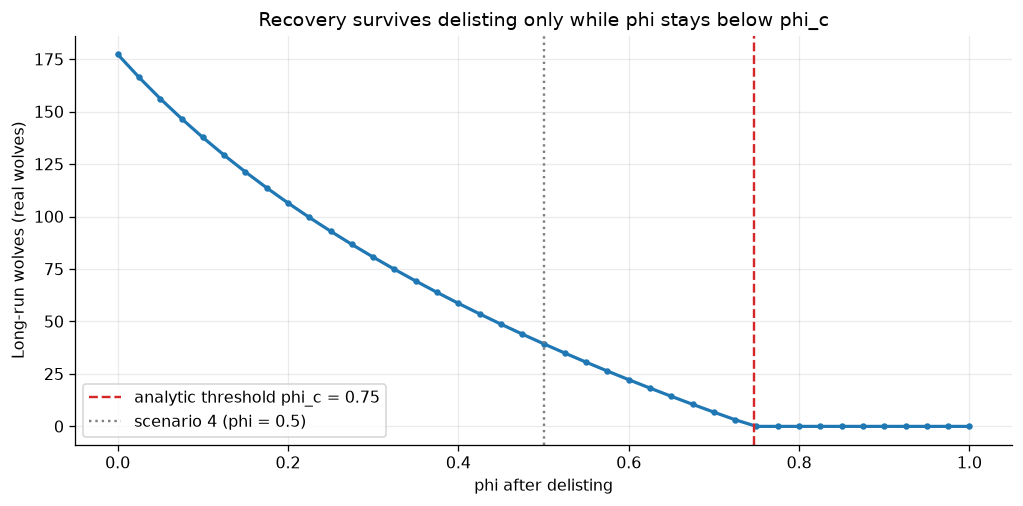

In [18]:
# 12c. Delisting: how much hunting can come back?
phi_del = np.linspace(0, 1, 41)
finals_del = [final_state(make_scenario(t_delist=t_delist_demo, phi_delisted=ph))[1] for ph in phi_del]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(phi_del, np.array(finals_del) * WOLF_UNIT, "o-", ms=3, lw=2)
ax.axvline(phi_c, color="tab:red", ls="--", label=f"analytic threshold phi_c = {phi_c:.2f}")
ax.axvline(REINTRO_PARAMS["phi_delisted"], color="gray", ls=":", label="scenario 4 (phi = 0.5)")
ax.set(xlabel="phi after delisting", ylabel="Long-run wolves (real wolves)",
       title="Recovery survives delisting only while phi stays below phi_c")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

**What the parameter choices change.**

- **Long-run wolves are most sensitive to $b$, $K_F$, $r$, $m$, and $\phi$** (12a). A 25% change in any of these shifts the wolf equilibrium by roughly 13–33%. Handling time $h$, interference $c$, and elk hunting $h_E$ barely matter at these values. Wolf conversion efficiency, wolf death rates, and elk habitat are the parameters most worth pinning down with data.
- **Extra habitat goes to the wolves, not the elk.** Raising $K_F$ by 25% raises wolves by 25% but elk by only about 7%. With wolves present, elk numbers are set mostly from the top down by predation ($a$ and $b$ move the elk equilibrium the most).
- **With an Allee effect, release size and protection both matter** (12b). With $A = 1.5$, wolves need roughly 16 or more released at $\phi = 0.2$, and they only recover for $\phi \lesssim 0.3$, far stricter than $\phi_c \approx 0.75$ without an Allee effect. Releasing more wolves does not push the protection limit beyond about 0.3: a big release cannot make up for weak protection.
- **Delisting has a sharp threshold at $\phi_c$** (12c). If post-delisting pressure stays below $\phi_c \approx 0.75$, wolves persist at a lower level; above it, they collapse to zero. The extinction model in `demo_wolf_extinction.py` is the far right end of this curve ($\phi = 1$).

## 13. Discussion and limitations

**What the model captures well**
- One connected story: the extinction model's end state is the reintroduction model's starting point, with the same habitat, elk hunting, and wolf-killing parameters.
- Why reintroduction is needed at all ($W = 0$ is invariant), and why a small release can grow into a large population (the positive eigenvalue at the wolf-free point).
- A clear division of labor: protection decides *whether* wolves recover and stay, while release size and starting elk mostly decide *how fast*, unless there is an Allee effect.
- A sharp, analytically predicted threshold $\phi_c$ for how much human-caused mortality wolves can tolerate, both before release and after delisting.
- Strong top-down control of elk, which roughly halve once wolves return. Northern-range elk counts in Yellowstone also fell by more than half after 1995, although cougars, bears, hunting, and drought contributed too.

**What it misses**
- Disease (mange, distemper), pack structure, and territoriality, which set real density limits.
- Space: dispersal out of the park, immigration from Canada and Idaho, and different rules inside and outside the park.
- Other predators (cougars, grizzly and black bears) and scavenging.
- Randomness, which matters most exactly when the population is small: right after release and near collapse.
- Weather and year-to-year variation in elk survival.

**Are the magnitudes realistic?** Wolf numbers are calibrated by choice of unit (1 unit ≈ 10 wolves), so the equilibrium of about 107 matches the park's roughly 100 wolves by construction. The recovery time of about 6 years is a genuine prediction and is close to what happened. Elk are an uncalibrated index, so only their relative change (about −46%) should be read from the model.

**Policy takeaway.** The release starts the recovery, but protection is what makes it last. In this model wolves persist only if at least about 25% of extinction-era human-caused deaths are permanently prevented ($\phi < 0.75$), and if small packs struggle to reproduce, the release must also be large enough and the protection much stronger.

## References

- NPS, Wolf Restoration: https://www.nps.gov/yell/learn/nature/wolf-restoration.htm
- NPS, 1995–96 Wolf Project Report: https://www.nps.gov/yell/learn/nature/upload/wolfreport_95-96_508.pdf
- CRS, Experimental Populations Under the ESA and Gray Wolves: https://www.everycrsreport.com/reports/R47581.html
- *Wyoming Farm Bureau Federation v. Babbitt*, 199 F.3d 1224 (10th Cir. 2000)
- NPS, 2025 Wolf/Cougar/Elk Project Annual Report: https://www.nps.gov/yell/learn/upload/2025-YELL-Wolf-Cougar-Elk-Project-Annual-Report-508.pdf
- Beddington, J. R. (1975). Mutual interference between parasites or predators and its effect on searching efficiency. *Journal of Animal Ecology*, 44, 331–340.
- DeAngelis, D. L., Goldstein, R. A., & O'Neill, R. V. (1975). A model for trophic interaction. *Ecology*, 56, 881–892.
- Courchamp, F., Clutton-Brock, T., & Grenfell, B. (1999). Inverse density dependence and the Allee effect. *Trends in Ecology & Evolution*, 14, 405–410.

## 14. Full protection ($\phi = 0$) vs. partial protection ($\phi = 0.25$)

The earlier sections use partial protection ($\phi = 0.2$), because the 10(j) rule still allowed problem wolves to be killed. Here we compare **full protection** ($\phi = 0$, all human-caused wolf deaths stop after the first release) with **partial protection** ($\phi = 0.25$). Everything else is unchanged.

First image: the full extinction-then-reintroduction timeline for each protection level, with elk and wolves on the same axes (same release, same starting point). Second image: the phase plane and equilibrium for each level, with the same nine starting points as Section 11a and shared axes so the equilibria can be compared directly.

In [ ]:
# Image 1: wolf and elk populations under two protection policies.
phis_compare = [0.0, 0.25]
compare_runs = {}

fig, axes = plt.subplots(2, 1, figsize=(5.0, 5.20), sharex=True)
for ax, phi in zip(axes, phis_compare):
    m = make_scenario(f"phi = {phi:g}", phi_protected=phi)
    s = simulate(m)
    E_inf, W_inf = final_state(m)
    compare_runs[phi] = (E_inf, W_inf)
    rt = recovery_time(s, REINTRO_PARAMS, W_inf)
    print(f"phi={phi:g}: equilibrium elk={E_inf:.1f}, wolves={W_inf:.2f} units "
          f"({W_inf * WOLF_UNIT:.0f} wolves); peak={s.y[1].max() * WOLF_UNIT:.0f} wolves; "
          f"time to 90%={rt:.1f} years")

    ax.plot(t_ext, sol_ext.y[0], color="tab:blue", lw=1.8, label="Elk")
    ax.plot(t_ext, sol_ext.y[1], color="tab:orange", lw=1.8, label="Wolves")
    ax.plot(s.t, s.y[0], color="tab:blue", lw=1.8)
    ax.plot(s.t, s.y[1], color="tab:orange", lw=1.8)
    ax.axvspan(t_ext[0], 0, color="0.92", zorder=0)
    ax.axvline(0, color="0.25", lw=0.9)
    ax.text(t_ext[0] + 2, 108, "Extinction", fontsize=8, va="top")
    ax.text(2, 108, "Reintroduction", fontsize=8, va="top")
    ax.axvline(REINTRO_PARAMS["t_release"], color="0.4", ls=":", lw=1.1,
               label="Release and protection begin")
    policy = "Full protection" if phi == 0 else "Partial protection"
    ax.set(title=f"{policy} ($\\phi={phi:g}$)", ylabel="Population (scaled units)")
    ax.grid(alpha=0.22)
    ax.legend(loc="upper right", fontsize=7.5)
axes[-1].set_xlabel("Years (0 = end of extinction run)")
fig.tight_layout()
fig.savefig(PAPER_FIGURES / "reintroduction_phi_0_vs_025_populations.pdf", dpi=300)
fig.savefig(PAPER_FIGURES / "reintroduction_phi_0_vs_025_populations.png", dpi=300)
plt.show()


In [ ]:
# Image 2: phase planes and equilibria under the same two policies.
xlim_c, ylim_c = (0, 1.1 * REINTRO_PARAMS["KF"]), (0, 25)

fig, axes = plt.subplots(2, 1, figsize=(5.0, 5.38), sharex=True, sharey=True)
for ax, phi in zip(axes, phis_compare):
    post = post_release_model(phi, f"phi = {phi:g}")
    post.plot_streamplot(xlim_c, ylim_c, ax=ax, density=0.55)
    for E0_, W0_ in starts:
        traj = post.solve((E0_, W0_), (0, 200), n_points=2001)
        ax.plot(traj.y[0], traj.y[1], color="#263746", lw=1.0, alpha=0.68)
        ax.scatter(E0_, W0_, s=22, color="black", zorder=5)
    E_inf, W_inf = compare_runs[phi]
    ax.scatter(E_inf, W_inf, s=140, marker="*", color="gold", edgecolors="black", zorder=6,
               label=f"Equilibrium ({E_inf:.1f}, {W_inf:.2f})")
    policy = "Full protection" if phi == 0 else "Partial protection"
    ax.set(title=f"{policy} ($\\phi={phi:g}$)", ylabel="Wolves (units)")
    ax.legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("Elk")
fig.tight_layout()
fig.savefig(PAPER_FIGURES / "reintroduction_phi_0_vs_025_equilibria.pdf", dpi=300)
fig.savefig(PAPER_FIGURES / "reintroduction_phi_0_vs_025_equilibria.png", dpi=300)
plt.show()
